# Endmembers in the data cloud: our version of Li & Bioucas-Dias (2008), Fig. 1

Fig. 1 of the MVSA paper (J. Li and J. M. Bioucas-Dias, *Minimum volume simplex
analysis: a fast algorithm to unmix hyperspectral data*, IGARSS 2008) projects the pixels to two dimensions and overlays the
true endmembers and those found by VCA, MVSA and NMF-MVT, for $p = 3$ and
$p = 10$. Its setup: $n = 10\,000$ pixels, Dirichlet($\mathbf 1$) abundances,
every pixel with an abundance above $0.8$ discarded (no pure pixels), noise-free.
The point it makes: VCA picks data points, so without pure pixels it lands
inside the cloud; MVSA's minimum-volume simplex reaches past the data to the
true vertices.

This notebook redraws it twice:

1. **Toy, known truth.** The paper's recipe with voter types in place of mineral
   spectra, so the true archetypes can be drawn.
2. **Senatorial data, 2013–2025.** Precincts in place of pixels, no truth.
   Every year, under both normalizations (per ballot and per vote), at several
   $p$.

Each in two projections:

- **PCA** (first two principal components of the precincts). Linear, so a
  simplex stays a simplex and an endmember outside the cloud stays outside. This
  is the paper's kind of projection.
- **UMAP**, fit on the precincts, endmembers placed with `transform`. Nonlinear:
  it keeps neighborhoods, not affine structure. An endmember is placed near the
  precincts it is closest to, so an MVSA vertex beyond the cloud is pulled back
  onto it. Read UMAP for *which part of the cloud* an archetype points at, not
  for *how far out* it is.

For $p \ge 4$ part 2 adds a third, linear view: the **archetype plane**, the
2-D plane inside the first $p - 1$ principal components that the MVSA vertices
spread out on most, which keeps more of the overshoot in view than PC 1 and PC 2.

Our methods: VCA and MVSA as in the paper (`src.unmixing`, MVSA initialized with
VCA); NMF is the pipeline's KL NMF (notebook 10), not NMF-MVT. Its columns are
rescaled to the data's mean column sum (`endmember_extraction.nmf`), so they need
not lie on the data's plane; the projections still place them, but distances
from the plane are dropped.

In [1]:
import contextlib
import io
import json
import pickle
import time
import sys
import warnings
from pathlib import Path

sys.path.append("..")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap  # umap-learn; notebook-only, not in requirements.txt
from scipy.optimize import linear_sum_assignment, linprog
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from src.config import load_config, set_normalization
from src.data import load_complete
from src.data.preprocessing import preprocess_from_config
from src.unmixing import extract_endmembers, method_params, vca
from src.unmixing.methods import params_tag

warnings.filterwarnings("ignore", message="sparse_svds failed")
warnings.filterwarnings("ignore", message="SNR estimation")
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")  # UMAP + random_state

# dataviz reference palette (as in notebook 15)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
mpl.rcParams.update({
    "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 120,
})

PS = [3, 10]  # the paper's two panels (toy)
config = load_config("../configs/config_2025.ini")  # toy: seed and method settings
SEED = config["unmixing"].getint("seed")
PARAMS = {m: method_params(config["unmixing"], m) for m in ["mvsa", "nmf"]}
CACHE = Path("../data/notebook_experiments/16_endmember_projections")
CACHE.mkdir(parents=True, exist_ok=True)

In [2]:
def run_vca(Y, p, seed=SEED):
    np.random.seed(seed)
    with contextlib.redirect_stdout(io.StringIO()):
        M, *_ = vca(Y, Endmembers=p, verbose="off")
    return M


def fit_all(Y, p):
    # (L, p) endmembers per method, same seed for each
    return {
        "VCA": run_vca(Y, p),
        "MVSA": extract_endmembers(Y, p, SEED, "mvsa", PARAMS["mvsa"]),
        "NMF": extract_endmembers(Y, p, SEED, "nmf", PARAMS["nmf"]),
    }


def match_error(M_hat, M):
    # ||M_hat - M||_F after matching columns (Hungarian on Euclidean distance)
    D = np.linalg.norm(M_hat[:, :, None] - M[:, None, :], axis=0)
    r, c = linear_sum_assignment(D)
    return float(np.linalg.norm(M_hat[:, r] - M[:, c]))


# Paper-style markers: hollow squares/diamonds so the true star shows inside
STYLE = {
    "true": dict(marker="*", s=120, color=INK, lw=0, zorder=7),
    "VCA": dict(marker="X", s=55, color=CAT[2], edgecolor="white", lw=0.6, zorder=6),
    "MVSA": dict(marker="s", s=75, facecolor="none", edgecolor=CAT[0], lw=1.6, zorder=5),
    "NMF": dict(marker="D", s=60, facecolor="none", edgecolor=CAT[1], lw=1.4, zorder=5),
}


def panel(ax, xy, ends, title, outline=None, dot=1.5, alpha=0.3, scale=1.0):
    # precinct cloud + each method's endmembers; outline = method whose simplex to draw
    ax.scatter(*xy.T, s=dot, color=MUTED, alpha=alpha, lw=0, rasterized=True,
               label="precincts", zorder=1)
    if outline is not None:
        v = ends[outline]
        ax.fill(*v.T, facecolor="none", edgecolor=STYLE[outline]["edgecolor"],
                lw=0.8, alpha=0.6, zorder=2)
    for name, e in ends.items():
        ax.scatter(*e.T, label=name, **{**STYLE[name], "s": STYLE[name]["s"] * scale})
    ax.set_title(title)


def projections(Y, ends_by_p, reducer=None):
    # 2-D coordinates of the precincts and of every method's endmembers, per p
    pca = PCA(2).fit(Y.T)
    if reducer is None:
        reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit(Y.T)
    out = {"pca": pca, "reducer": reducer,
           "xy": {"PCA": pca.transform(Y.T), "UMAP": reducer.embedding_}}
    for p, ends in ends_by_p.items():
        out[p] = {
            "PCA": {k: pca.transform(M.T) for k, M in ends.items()},
            "UMAP": {k: reducer.transform(M.T) for k, M in ends.items()},
        }
    return out


def figure(P_by_p, suptitle, dot=1.5, alpha=0.3):
    # rows p, columns PCA / UMAP; P_by_p[p] = projections(...) holding that p
    fig, axes = plt.subplots(len(PS), 2, figsize=(8.4, 3.9 * len(PS)))
    for row, p in zip(axes, PS):
        P = P_by_p[p]
        ev = P["pca"].explained_variance_ratio_
        panel(row[0], P["xy"]["PCA"], P[p]["PCA"], f"PCA, p = {p}",
              outline="MVSA" if p == 3 else None, dot=dot, alpha=alpha)
        row[0].set(xlabel=f"PC 1 ({ev[0]:.0%} of variance)",
                   ylabel=f"PC 2 ({ev[1]:.0%} of variance)")
        panel(row[1], P["xy"]["UMAP"], P[p]["UMAP"], f"UMAP, p = {p}", dot=dot, alpha=alpha)
        row[1].set(xlabel="UMAP 1", ylabel="UMAP 2", xticklabels=[], yticklabels=[])
    h, lab = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, lab, loc="upper center", ncol=len(lab), bbox_to_anchor=(0.5, 1.0))
    precincts = leg.legend_handles[0]  # the legend's copy, not the plotted points
    precincts.set_sizes([18])
    precincts.set_alpha(1)
    fig.suptitle(suptitle, y=1.03)
    fig.tight_layout()
    return fig

## 1. Toy: the paper's recipe, with voter types

$L = 24$ candidates. Each type's loadings are drawn from Beta(0.5, 2): most
candidates are rarely marked, a few often (capped at 0.95). Abundances are
Dirichlet($\mathbf 1$) and any precinct with an abundance above $0.8$ is
dropped, so there are no near-pure precincts, as in the paper. Noise-free
($\mathbf Y = \mathbf M\mathbf S$), like its Fig. 1; set `B_TOY` to a ballot
count for binomial noise. Error is $\lVert\hat{\mathbf M}-\mathbf M\rVert_F$
after matching columns, the paper's Table 1 measure.

In [3]:
L_TOY, N_TOY, B_TOY = 24, 10_000, None  # B_TOY = e.g. 500 for binomial noise
rng = np.random.default_rng(SEED)


def toy(p):
    M = np.minimum(rng.beta(0.5, 2.0, (L_TOY, p)), 0.95)
    S = rng.dirichlet(np.ones(p), 4 * N_TOY)
    S = S[S.max(axis=1) <= 0.8][:N_TOY].T
    Y = M @ S
    if B_TOY:
        Y = rng.binomial(B_TOY, Y) / B_TOY
    return Y, M


toy_runs = {}
for p in PS:
    Y, M = toy(p)
    toy_runs[p] = dict(Y=Y, M=M, ends={"true": M, **fit_all(Y, p)})

pd.DataFrame(
    {p: {k: match_error(E, r["M"]) for k, E in r["ends"].items() if k != "true"}
     for p, r in toy_runs.items()}
).rename_axis("method").rename(columns=lambda p: f"p = {p}").round(3)

,p = 3,p = 10
method,,
VCA,0.414,1.327
MVSA,0.015,0.005
NMF,0.300,1.386


Each $p$ is its own toy data set, so the projections are fit per $p$ and the
figure is assembled from two runs.

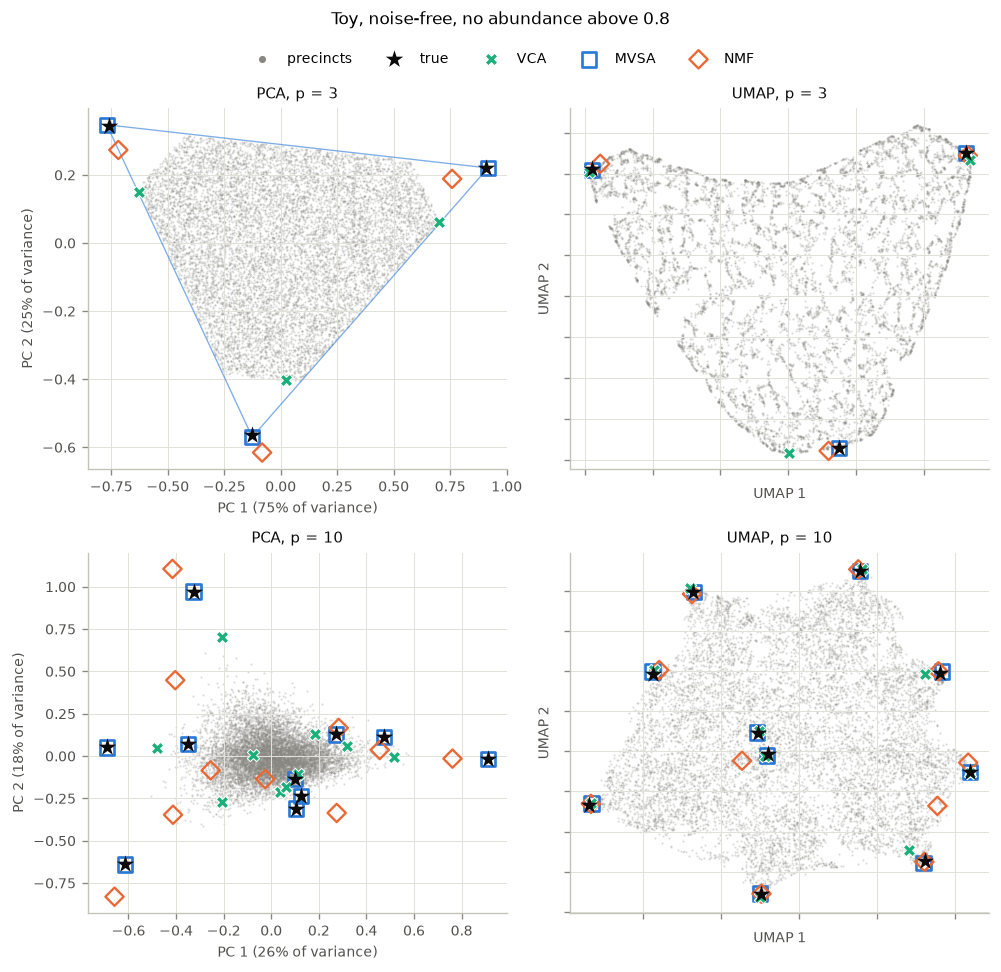

In [4]:
toy_P = {p: projections(r["Y"], {p: r["ends"]}) for p, r in toy_runs.items()}
figure(toy_P, "Toy, noise-free, no abundance above 0.8")
plt.show()

## 2. Senatorial data: across years, $p$ and normalization

Precincts as each year's config preprocesses them, under both normalizations
the site offers:

- **per ballot**: 2019 and 2022 divide by valid ballots, 2025 by actual voters
  (its valid-ballot count is not a ballot count). 2013 and 2016 have no ballot
  count, so they have no per-ballot run.
- **per vote** (vote-sum): every year.

MVSA and NMF endmembers are the config-seed runs that
`scripts/bake_distinctness.py` cached for the site's distinctness chart (computed
here if missing). VCA is computed here. PCA and UMAP are fit once per year and
normalization, on all precincts, and shared across $p$; the UMAP fits are cached
(about 2 min each the first time; delete the pickle to refit).

Figures show `P_FIG`. The summary at the end covers every cached $p$ (`P_ALL`).

In [5]:
P_FIG = [2, 3, 4, 5, 6, 7, 10]   # the site's sweep range + the paper's p = 10
P_ALL = list(range(2, 13))       # every p the distinctness bake caches
YEARS = ["2013", "2016", "2019", "2022", "2025"]
NORMS = {"ballot": "per ballot", "vote_sum": "per vote"}
UNIT = {"ballot": "vote/ballot", "vote_sum": "vote/vote"}
COMBOS = [("ballot", y) for y in ["2019", "2022", "2025"]] + [("vote_sum", y) for y in YEARS]
BAKE = Path("../data/notebook_experiments/08_distinctness")
MANIFEST = json.loads(Path("../site/data/manifest.json").read_text())


def combo_config(norm, year):
    # the year's config; "ballot" keeps its own per-ballot normalization
    return set_normalization(load_config(f"../configs/config_{year}.ini"),
                             None if norm == "ballot" else norm)


def hysime_k(norm, year):
    meta = MANIFEST["methods"]["mvsa"]["norms"].get(norm, {}).get("years_meta", {})
    return meta.get(year, {}).get("hysime_kf")


def cached_endmembers(path, compute):
    if path.exists():
        return np.load(path)
    M = compute()
    np.save(path, M)
    return M


def load_combo(norm, year):
    cfg = combo_config(norm, year)
    nname = cfg["preprocessing"]["normalization"]
    seed = cfg["unmixing"].getint("seed")
    params = {m: method_params(cfg["unmixing"], m) for m in ["mvsa", "nmf"]}
    Y = preprocess_from_config(load_complete(cfg), cfg, verbose=False).Y
    ends = {}
    for p in P_ALL:
        ends[p] = {"VCA": cached_endmembers(
            CACHE / f"{year}_{nname}_vca_p{p}_seed{seed}.npy", lambda: run_vca(Y, p, seed))}
        for key, name in [("mvsa", "MVSA"), ("nmf", "NMF")]:
            fname = f"endm_p{p}_seed{seed}_{params_tag(key, params[key])}.npy"
            path = BAKE / nname / year / fname
            if not path.exists():
                path = CACHE / f"{year}_{nname}_{fname}"
            ends[p][name] = cached_endmembers(
                path, lambda: extract_endmembers(Y, p, seed, key, params[key]))
    upath = CACHE / f"{year}_{nname}_umap_nn30_md0.1_seed{seed}.pkl"
    if upath.exists():
        reducer = pickle.loads(upath.read_bytes())
    else:
        reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=seed).fit(Y.T)
        upath.write_bytes(pickle.dumps(reducer))
    P = projections(Y, {p: ends[p] for p in P_FIG}, reducer=reducer)
    return dict(Y=Y, ends=ends, P=P, normalization=nname, k=hysime_k(norm, year))


RUNS = {}
for norm, year in COMBOS:
    t0 = time.time()
    RUNS[norm, year] = load_combo(norm, year)
    R = RUNS[norm, year]
    print(f"{year} {NORMS[norm]:>10} ({R['normalization']}): Y {R['Y'].shape}, "
          f"HySime k = {R['k']}, {time.time() - t0:.0f}s")

2019 per ballot (valid_ballots): Y (32, 85113), HySime k = 5, 1s


2022 per ballot (valid_ballots): Y (34, 105033), HySime k = 6, 1s


2025 per ballot (actual_voters): Y (42, 92486), HySime k = 6, 1s


2013   per vote (vote_sum): Y (19, 59675), HySime k = 3, 0s


2016   per vote (vote_sum): Y (32, 22985), HySime k = 5, 0s


2019   per vote (vote_sum): Y (32, 85113), HySime k = 4, 1s


2022   per vote (vote_sum): Y (34, 105033), HySime k = 4, 1s


2025   per vote (vote_sum): Y (42, 92486), HySime k = 6, 1s


### The grids

One figure per normalization and projection: a row per year, a column per $p$.
A panel titled with **= k** is at that year's HySime estimate. The number in the
corner is MVSA's most negative loading (in the normalization's units), since the
UMAP panels cannot show how far out the vertices are. The MVSA simplex is drawn
for $p \le 3$ in PCA. Axes are per panel: as $p$ grows and the MVSA vertices move
out, the precinct cloud shrinks in the PCA panels.

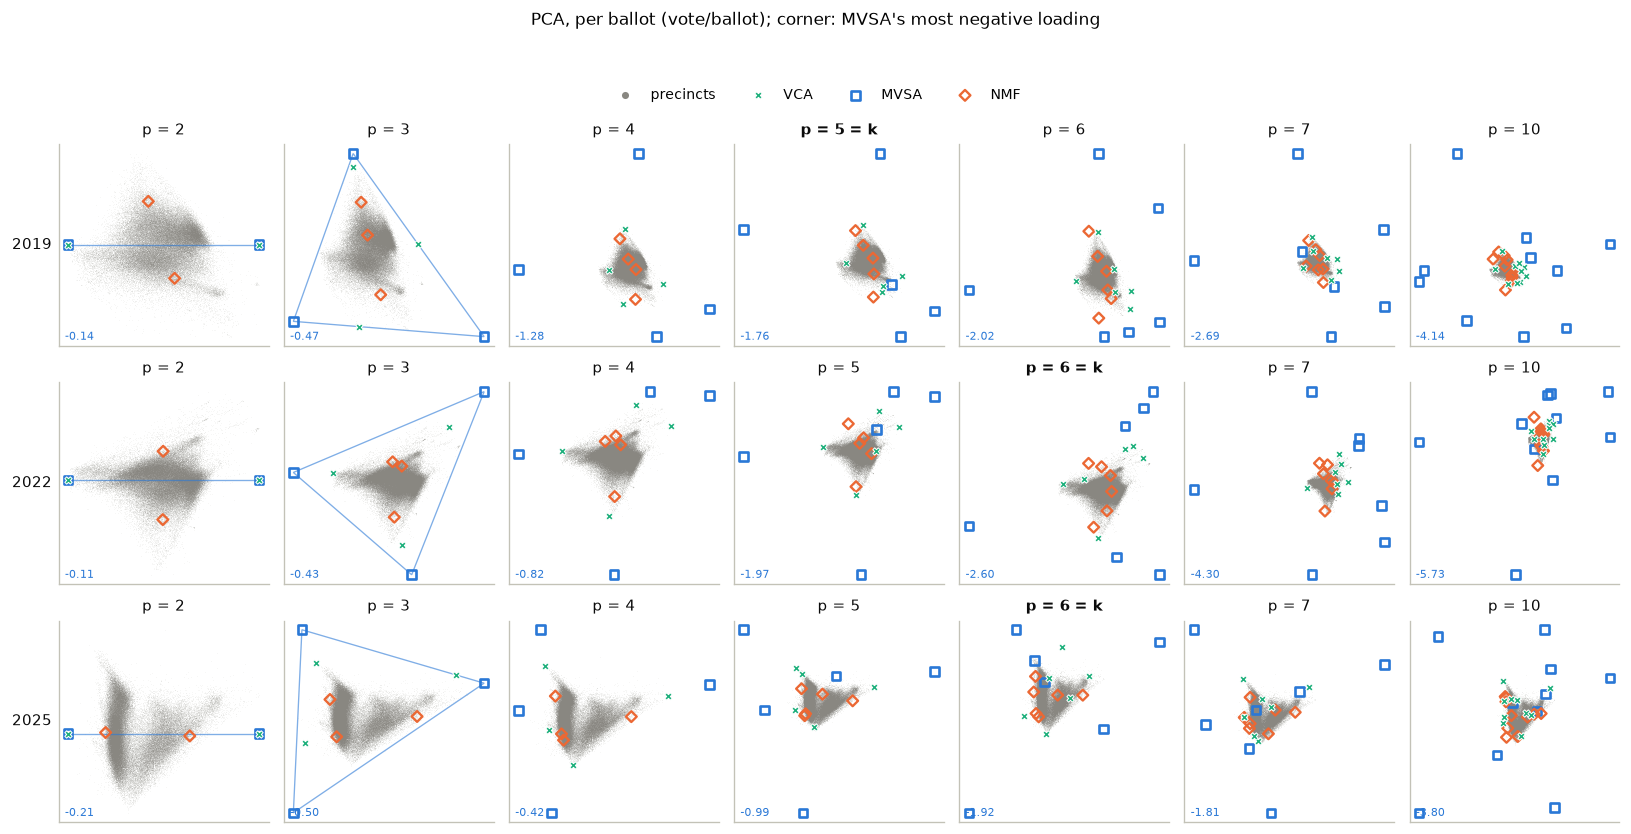

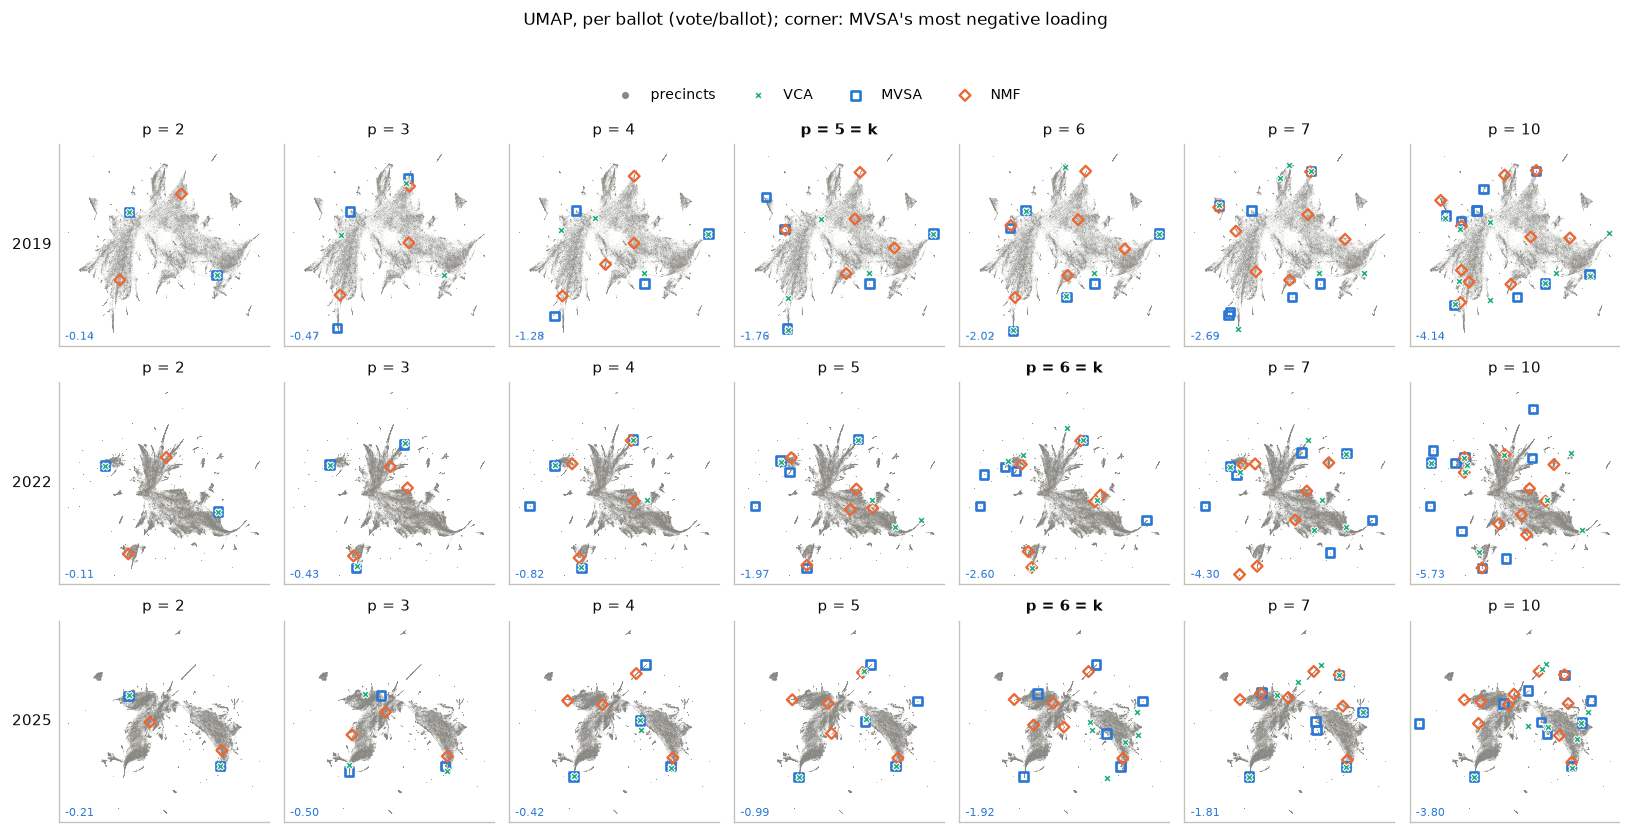

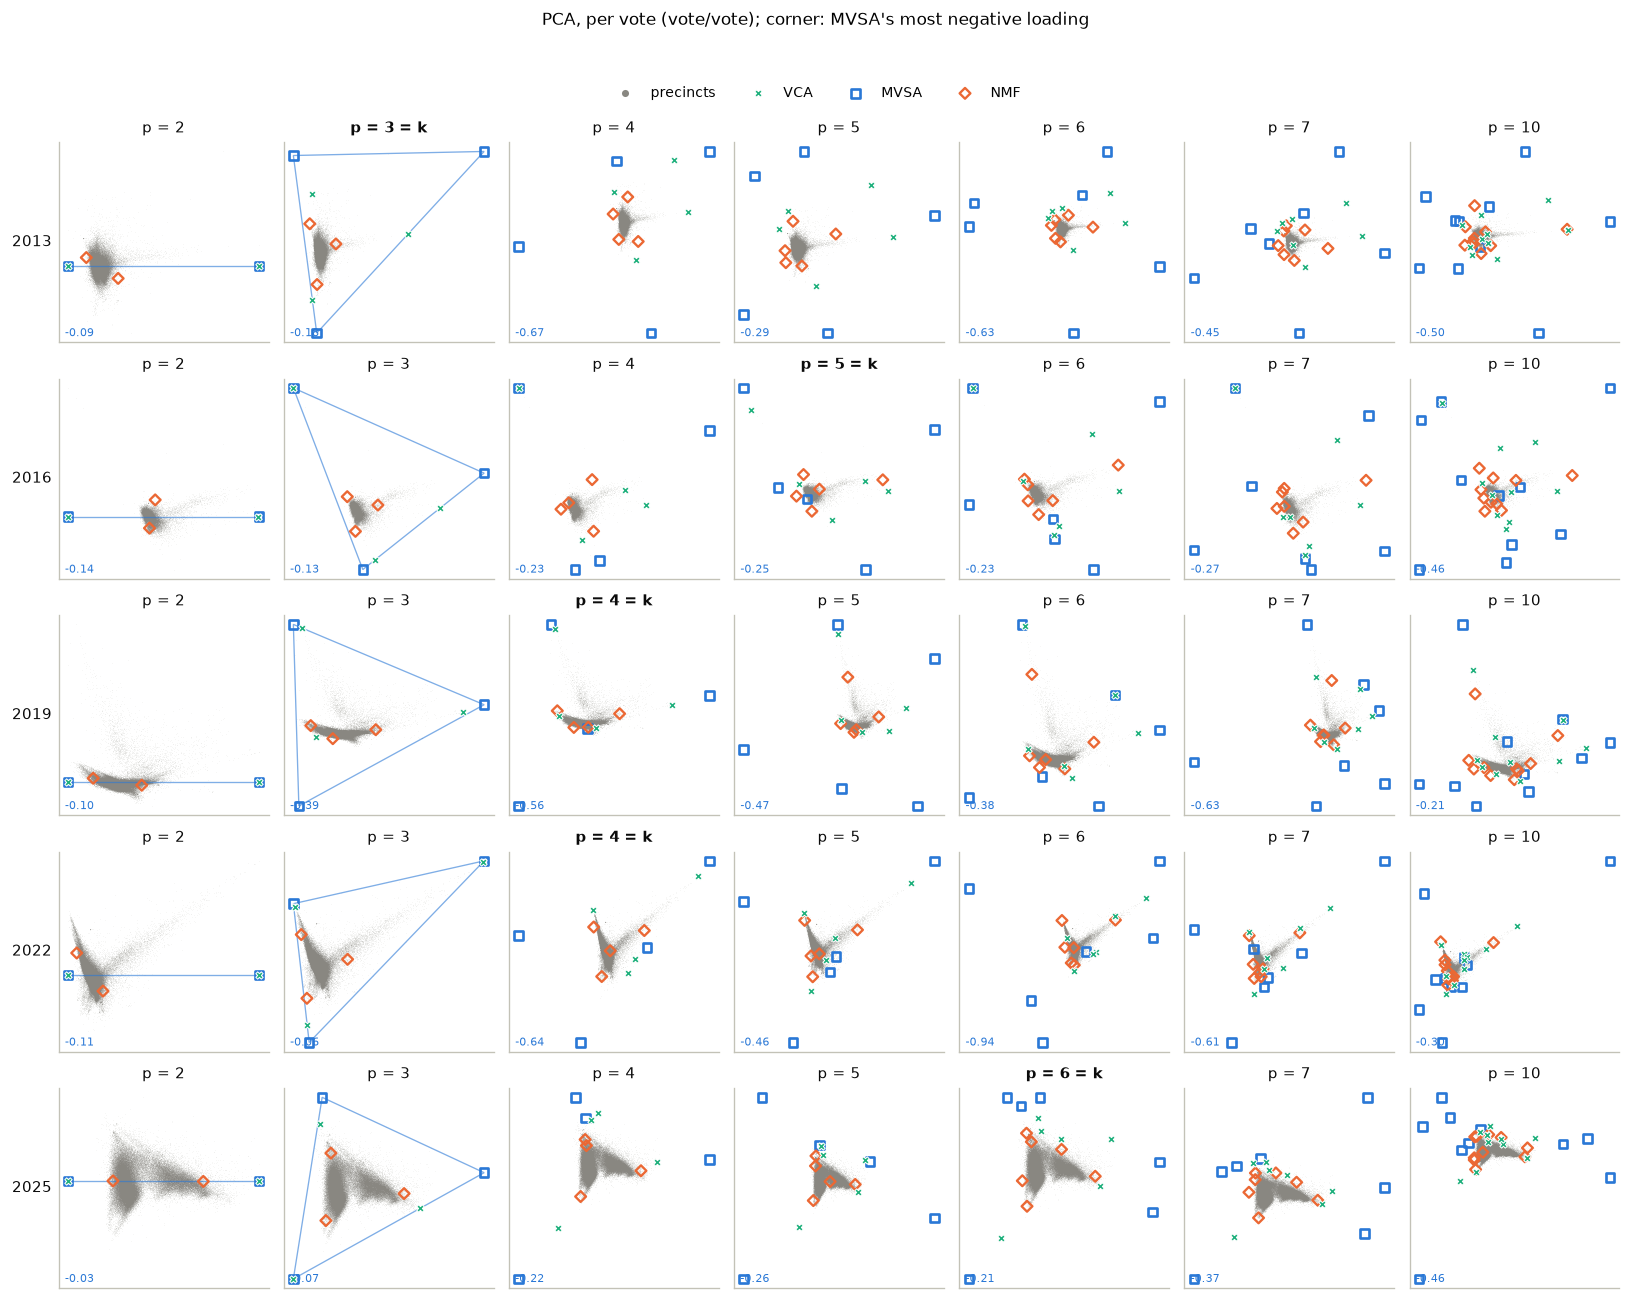

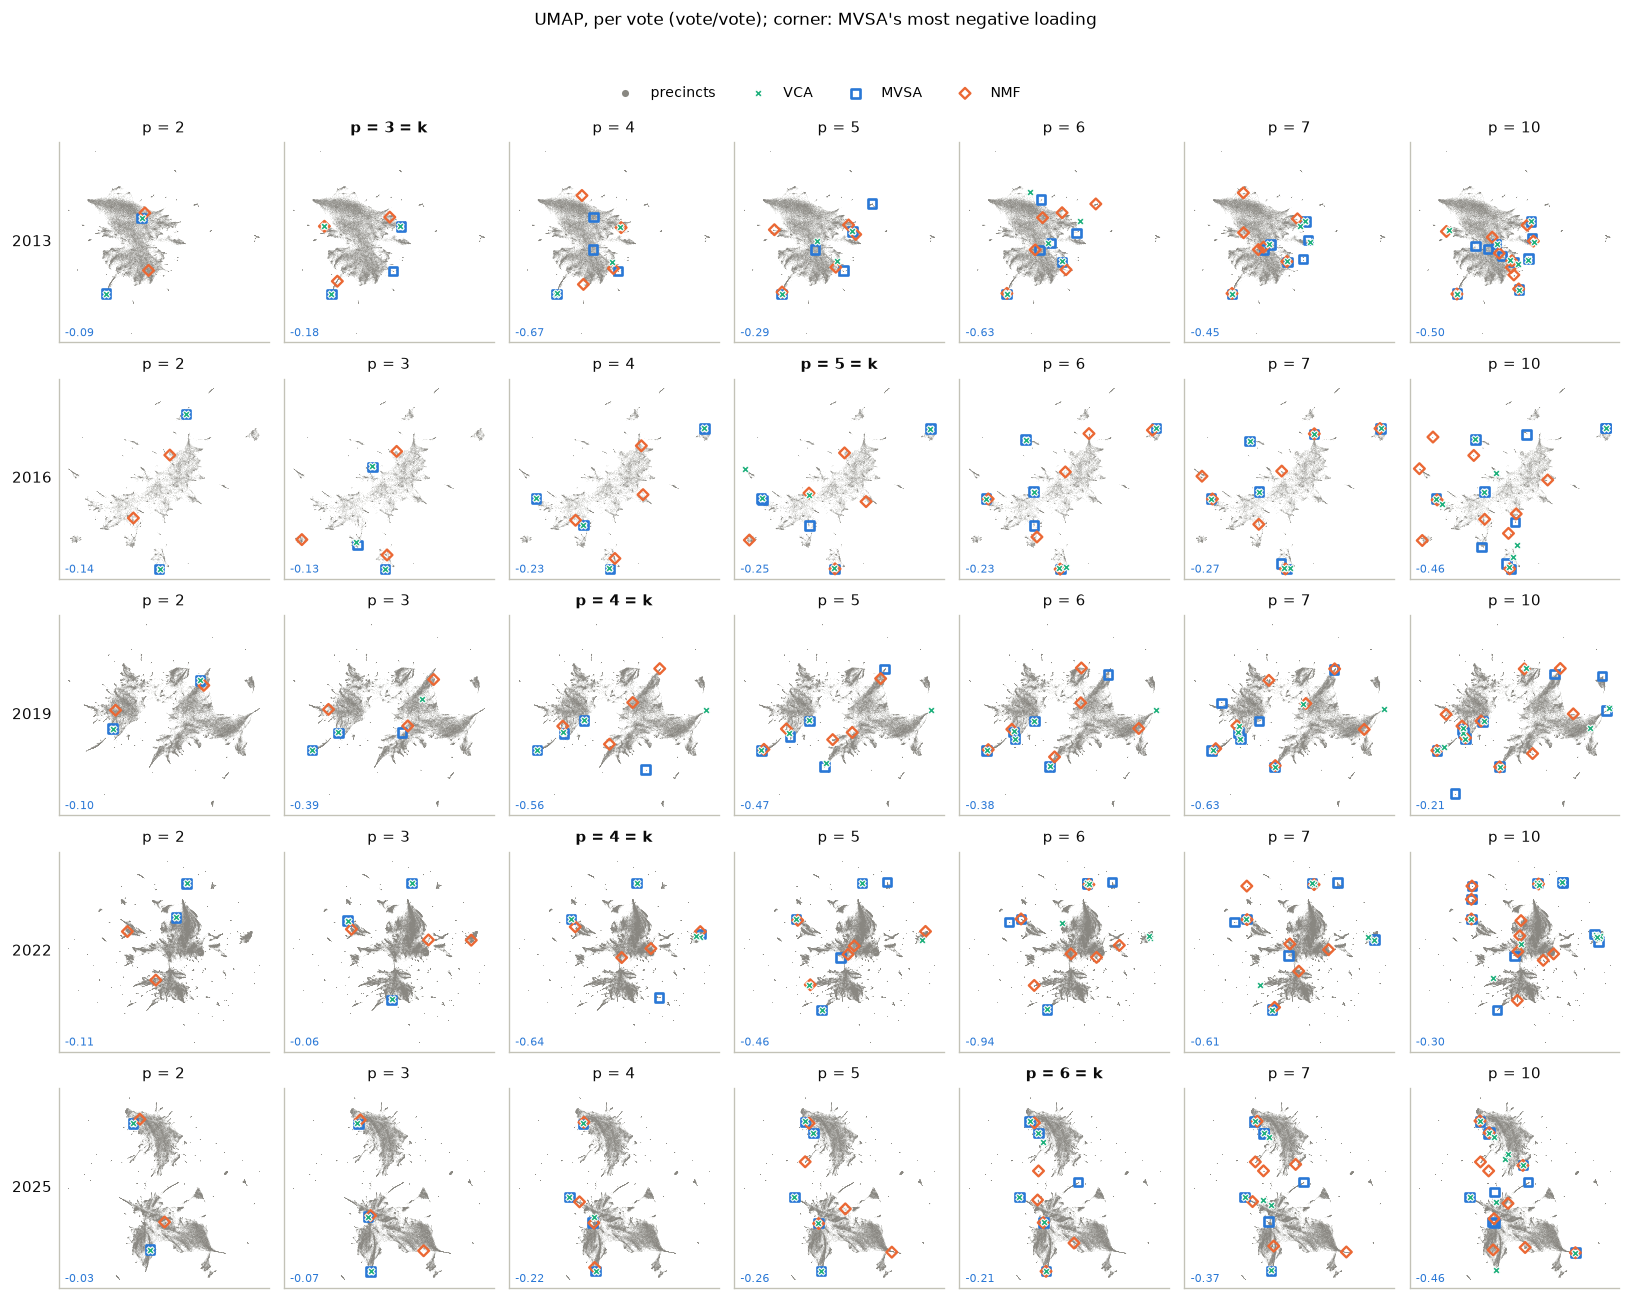

In [6]:
def grid(norm, proj):
    years = [y for n, y in COMBOS if n == norm]
    fig, axes = plt.subplots(len(years), len(P_FIG), squeeze=False,
                             figsize=(1.95 * len(P_FIG), 1.95 * len(years) + 0.5))
    for r, year in enumerate(years):
        R = RUNS[norm, year]
        for c, p in enumerate(P_FIG):
            ax = axes[r, c]
            panel(ax, R["P"]["xy"][proj], R["P"][p][proj],
                  f"p = {p}" + (" = k" if p == R["k"] else ""),
                  outline="MVSA" if proj == "PCA" and p <= 3 else None,
                  dot=0.4, alpha=0.08, scale=0.35)
            if p == R["k"]:
                ax.title.set_fontweight("bold")
            ax.text(0.03, 0.03, f"{R['ends'][p]['MVSA'].min():.2f}", transform=ax.transAxes,
                    fontsize=6.5, color=STYLE["MVSA"]["edgecolor"])
            ax.set(xticks=[], yticks=[])
            ax.grid(False)
        axes[r, 0].set_ylabel(year, rotation=0, ha="right", va="center",
                              fontsize=9, color=INK)
    h, lab = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, lab, loc="upper center", ncol=len(lab), bbox_to_anchor=(0.5, 1.0))
    leg.legend_handles[0].set_sizes([18])
    leg.legend_handles[0].set_alpha(1)
    fig.suptitle(f"{proj}, {NORMS[norm]} ({UNIT[norm]}); "
                 f"corner: MVSA's most negative loading", y=1.0 + 0.25 / len(years))
    fig.tight_layout()
    return fig


for norm in NORMS:
    for proj in ["PCA", "UMAP"]:
        grid(norm, proj)
        plt.show()

### How far out are the endmembers, for every $p$?

Per method, year, normalization and $p$ in `P_ALL`:

- **min loading:** the most negative entry of $\hat{\mathbf M}$ (below zero
  means outside the nonnegative orthant, notebook 15);
- **distance to nearest precinct:** the median over endmembers of the Euclidean
  distance to the closest precinct. VCA picks precincts but returns them
  projected onto the $p$-dimensional subspace it fits (`Rp[:, indice]` in
  `endmember_extraction.vca`), so its distance is that precinct's residual off
  the subspace, not zero.

- **distance / cloud radius:** that distance divided by the cloud's RMS radius
  $\sqrt{\tfrac1n\sum_j \lVert \mathbf y_j - \bar{\mathbf y}\rVert^2}$.

The first two are in the normalization's units. Per-vote clouds are 7–10 times
tighter than per-ballot ones, so raw distances make per-vote archetypes look far
closer than they are; the ratio puts both normalizations on one scale. Dots mark
each year's HySime $k$.

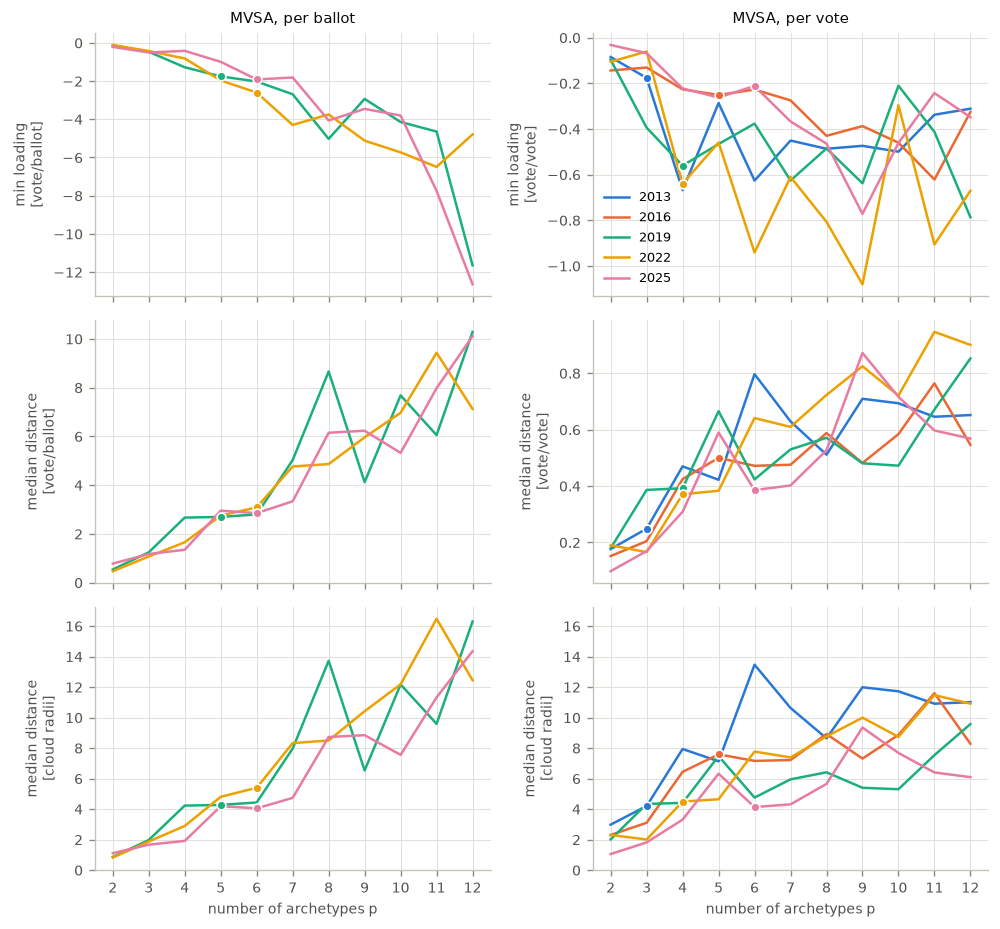

p                            2     3     4     5     6     7     8     9   \
normalization year method                                                   
per ballot    2019 MVSA   -0.14 -0.47 -1.28 -1.76 -2.02 -2.69 -5.03 -2.93   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.14 -0.23 -0.32 -0.33 -0.25 -0.21 -0.29 -0.42   
              2022 MVSA   -0.11 -0.43 -0.82 -1.97 -2.60 -4.30 -3.74 -5.12   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.11 -0.20 -0.28 -0.28 -0.29 -0.28 -0.41 -0.30   
              2025 MVSA   -0.21 -0.50 -0.42 -0.99 -1.92 -1.81 -4.06 -3.46   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.21 -0.23 -0.16 -0.19 -0.36 -0.19 -0.19 -0.28   
per vote      2013 MVSA   -0.09 -0.18 -0.67 -0.29 -0.63 -0.45 -0.49 -0.47   
                   NMF     0.01  0.01  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.09 -0.07 -0.08 -0.19 -0.19 -0.14 -0.14 -0.17   
              2016 MVSA   -0.14 -0.13 -0.23 -0.25 -0.23 -0.27 -0.43 -0.39   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.14 -0.13 -0.23 -0.19 -0.23 -0.14 -0.16 -0.17   
              2019 MVSA   -0.10 -0.39 -0.56 -0.47 -0.38 -0.63 -0.49 -0.64   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.10 -0.20 -0.21 -0.12 -0.13 -0.09 -0.08 -0.10   
              2022 MVSA   -0.11 -0.06 -0.64 -0.46 -0.94 -0.61 -0.81 -1.08   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.11 -0.06 -0.06 -0.06 -0.08 -0.08 -0.06 -0.06   
              2025 MVSA   -0.03 -0.07 -0.22 -0.26 -0.21 -0.37 -0.46 -0.77   
                   NMF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
                   VCA    -0.03 -0.04 -0.08 -0.11 -0.15 -0.08 -0.08 -0.08   

p                            10    11     12  
normalization year method                     
per ballot    2019 MVSA   -4.14 -4.64 -11.65  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.30 -0.29  -0.45  
              2022 MVSA   -5.73 -6.49  -4.79  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.36 -0.51  -0.40  
              2025 MVSA   -3.80 -7.75 -12.64  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.31 -0.20  -0.30  
per vote      2013 MVSA   -0.50 -0.34  -0.31  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.15 -0.12  -0.13  
              2016 MVSA   -0.46 -0.62  -0.33  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.12 -0.11  -0.09  
              2019 MVSA   -0.21 -0.41  -0.79  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.10 -0.11  -0.12  
              2022 MVSA   -0.30 -0.91  -0.67  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.09 -0.09  -0.09  
              2025 MVSA   -0.46 -0.24  -0.35  
                   NMF     0.00  0.00   0.00  
                   VCA    -0.08 -0.07  -0.10

In [7]:
rows = []
for (norm, year), R in RUNS.items():
    Y = R["Y"]
    nn = NearestNeighbors(n_neighbors=1).fit(Y.T)
    radius = np.sqrt(((Y - Y.mean(axis=1, keepdims=True)) ** 2).sum(axis=0).mean())
    for p in P_ALL:
        for name, M in R["ends"][p].items():
            d, _ = nn.kneighbors(M.T)
            rows.append({"normalization": NORMS[norm], "year": year, "p": p, "method": name,
                         "min loading": M.min(), "median distance": float(np.median(d)),
                         "distance / radius": float(np.median(d)) / radius})
far = pd.DataFrame(rows)

ROWS = {"min loading": "min loading\n[{u}]", "median distance": "median distance\n[{u}]",
        "distance / radius": "median distance\n[cloud radii]"}
fig, axes = plt.subplots(3, 2, figsize=(8.4, 7.8), sharex=True)
for c, norm in enumerate(NORMS):
    for r, col in enumerate(ROWS):
        ax = axes[r, c]
        for i, year in enumerate(YEARS):
            d = far[(far.normalization == NORMS[norm]) & (far.year == year)
                    & (far.method == "MVSA")].set_index("p")[col]
            if d.empty:
                continue
            ax.plot(d.index, d.values, color=CAT[i], lw=1.5, label=year)
            k = RUNS[norm, year]["k"]
            if k in d.index:
                ax.scatter([k], [d[k]], color=CAT[i], s=28, zorder=3, edgecolor="white")
        ax.set_title(f"MVSA, {NORMS[norm]}" if r == 0 else "")
        ax.set_ylabel(ROWS[col].format(u=UNIT[norm]))
    axes[-1, c].set_xlabel("number of archetypes p")
    axes[-1, c].set_xticks(P_ALL)
top = max(ax.get_ylim()[1] for ax in axes[2])  # cloud radii: one scale for both
for ax in axes[2]:
    ax.set_ylim(0, top)
axes[0, 1].legend(loc="lower left", fontsize=7.5)
fig.tight_layout()
plt.show()

far.pivot_table(index=["normalization", "year", "method"], columns="p",
                values="min loading").round(2)

In [8]:
far.pivot_table(index=["normalization", "year", "method"], columns="p",
                values="distance / radius").round(1)

p                           2    3    4    5     6     7     8     9     10  \
normalization year method                                                     
per ballot    2019 MVSA    0.9  2.0  4.2  4.3   4.4   8.0  13.7   6.5  12.2   
                   NMF     0.3  0.4  0.5  0.7   0.9   1.0   1.0   1.2   1.3   
                   VCA     0.9  0.9  1.0  0.9   1.3   1.1   1.0   1.3   1.4   
              2022 MVSA    0.8  1.9  2.9  4.8   5.4   8.3   8.5  10.4  12.2   
                   NMF     0.3  0.5  0.8  0.9   1.1   1.2   1.2   1.6   1.2   
                   VCA     0.8  1.0  1.3  1.4   1.5   1.9   1.5   1.4   1.6   
              2025 MVSA    1.1  1.7  1.9  4.2   4.0   4.7   8.7   8.8   7.6   
                   NMF     0.2  0.3  0.6  0.7   0.7   0.8   0.9   1.0   1.0   
                   VCA     1.1  1.0  1.1  1.1   1.4   1.0   0.9   1.4   1.3   
per vote      2013 MVSA    3.0  4.2  7.9  7.1  13.5  10.6   8.6  12.0  11.7   
                   NMF     0.4  0.8  1.2  1.3   1.2   1.9   1.8   2.4   2.4   
                   VCA     3.0  1.7  3.3  3.2   3.9   3.7   3.9   3.0   2.6   
              2016 MVSA    2.3  3.1  6.4  7.6   7.2   7.2   8.9   7.3   8.9   
                   NMF     0.5  0.7  0.9  1.0   0.9   1.1   1.3   1.5   1.7   
                   VCA     2.3  2.3  3.0  4.1   3.9   4.0   3.8   3.6   3.5   
              2019 MVSA    2.0  4.3  4.4  7.5   4.8   5.9   6.4   5.4   5.3   
                   NMF     0.2  0.4  0.5  0.7   0.8   0.7   0.9   1.0   1.1   
                   VCA     2.0  2.9  2.5  2.5   2.1   1.8   2.0   1.8   1.7   
              2022 MVSA    2.3  2.0  4.5  4.6   7.8   7.4   8.8  10.0   8.7   
                   NMF     0.3  0.6  0.7  0.7   0.8   1.0   0.9   1.2   1.5   
                   VCA     2.3  1.5  2.0  1.8   1.8   1.7   1.6   1.6   1.8   
              2025 MVSA    1.0  1.8  3.3  6.3   4.1   4.3   5.6   9.3   7.7   
                   NMF     0.2  0.3  0.5  0.6   0.8   0.9   0.9   1.1   1.1   
                   VCA     1.0  1.0  1.6  2.8   2.6   2.2   2.1   2.5   2.0   

p                            11    12  
normalization year method              
per ballot    2019 MVSA     9.6  16.3  
                   NMF      1.8   1.6  
                   VCA      1.1   1.2  
              2022 MVSA    16.5  12.4  
                   NMF      1.4   2.0  
                   VCA      1.8   1.5  
              2025 MVSA    11.3  14.3  
                   NMF      1.5   1.6  
                   VCA      0.9   1.2  
per vote      2013 MVSA    10.9  11.0  
                   NMF      2.8   2.8  
                   VCA      2.6   2.5  
              2016 MVSA    11.6   8.3  
                   NMF      1.8   1.9  
                   VCA      2.7   2.5  
              2019 MVSA     7.5   9.6  
                   NMF      1.3   1.3  
                   VCA      1.8   1.8  
              2022 MVSA    11.5  10.9  
                   NMF      1.3   1.6  
                   VCA      2.1   1.5  
              2025 MVSA     6.4   6.1  
                   NMF      1.2   1.2  
                   VCA      1.7   1.4

### An archetype plane for $p \ge 4$

The PCA panels keep two of the $p - 1$ dimensions the simplex spans. At $p = 3$
that loses nothing; from $p = 4$ a vertex can sit far out along PC 3 and still
land on the cloud. A linear projection keeps convex combinations, so the reading
is one-way:

- a vertex **outside** the projected cloud is outside the precincts' convex hull
  in $p - 1$ dimensions as well;
- a vertex **inside** it may still be outside, along a dropped direction.

So the choice of plane matters. Per $p$, in two steps:

1. PCA with $p - 1$ components on the precincts: the subspace the simplex lives
   in (MVSA fits in a $p$-dimensional subspace, the same one up to centering).
2. A 2-D plane inside it. PCA on the precincts again would give PC 1 and PC 2
   back (PCA's components are nested), so the plane is fit to the MVSA vertices
   instead: the two directions along which the $p$ vertices spread most. The
   precincts and all three methods' endmembers are projected onto it.

At $p = 3$ this is the PCA panel, rotated. The plane is MVSA's (`PLANE_BY`): VCA
and NMF are drawn on it but did not choose it, and unlike PC 1 and PC 2 its axes
mean something different at each $p$. The thin gray line is the precincts' hull
in the plane, the MVSA-colored one the shadow of the MVSA simplex (the hull of
its projected vertices). The title counts the MVSA vertices outside the
projected cloud.

In [9]:
PLANE_BY = "MVSA"                       # whose vertices the archetype plane is fit to
P_PLANE = [3] + [p for p in P_FIG if p >= 4]
PLANES = {"PCA": "PCA (PC 1, PC 2)", "arch": f"archetype plane ({PLANE_BY})"}


def plane_coords(R, p):
    # precincts and endmembers in the first p - 1 PCs, then on each 2-D plane
    pca = PCA(p - 1).fit(R["Y"].T)
    Z = pca.transform(R["Y"].T)
    Ze = {m: pca.transform(M.T) for m, M in R["ends"][p].items()}
    E = Ze[PLANE_BY] - Ze[PLANE_BY].mean(axis=0)
    out = {"Z": Z, "Ze": Ze}
    for name, V in [("PCA", np.eye(p - 1)[:, :2]),
                    ("arch", PCA(2).fit(Ze[PLANE_BY]).components_.T)]:
        xy, ends = Z @ V, {m: z @ V for m, z in Ze.items()}
        out[name] = dict(
            xy=xy, ends=ends,
            captured=float(((E @ V) ** 2).sum() / (E ** 2).sum()),  # vertex spread kept
            outside=int(outside_2d(xy, ends[PLANE_BY]).sum()),
        )
    return out


def outside_2d(cloud, pts, tol=1e-8):
    # points outside the convex hull of the 2-D cloud; on the hull counts as inside,
    # as in the linear program below (a vertex can be a precinct: 2016 per vote, p = 3)
    eq = ConvexHull(cloud).equations  # unit normals, inside where n·x + b <= 0
    return (pts @ eq[:, :2].T + eq[:, 2]).max(axis=1) > tol * np.abs(cloud).max()


def outside_lp(Z, pts):
    # points outside the convex hull of Z (n, d): is z a convex combination of rows of Z?
    A = np.vstack([Z.T, np.ones(len(Z))])
    return np.array([
        linprog(np.zeros(len(Z)), A_eq=A, b_eq=np.r_[z, 1], bounds=(0, None),
                method="highs").status != 0
        for z in pts
    ])


def plane_panel(ax, C, title, scale=0.35, dot=0.4, alpha=0.08):
    # title gets the count of PLANE_BY vertices outside the projected cloud
    p = len(C["ends"][PLANE_BY])
    panel(ax, C["xy"], C["ends"], f"{title} · {C['outside']}/{p} out",
          dot=dot, alpha=alpha, scale=scale)
    for pts, color, lw in [(C["xy"], MUTED, 0.6), (C["ends"][PLANE_BY], STYLE[PLANE_BY]["edgecolor"], 0.8)]:
        h = ConvexHull(pts)
        ax.fill(*pts[h.vertices].T, facecolor="none", edgecolor=color, lw=lw, alpha=0.7, zorder=2)
    ax.set(xticks=[], yticks=[])
    ax.grid(False)


t0 = time.time()
COORDS = {key: {p: plane_coords(R, p) for p in P_PLANE} for key, R in RUNS.items()}
print(f"{len(COORDS)} runs × {len(P_PLANE)} p: {time.time() - t0:.0f}s")

8 runs × 6 p: 1s


Both planes side by side for 2025, per ballot: the top row is the PCA grid's
row, the bottom row the archetype plane.

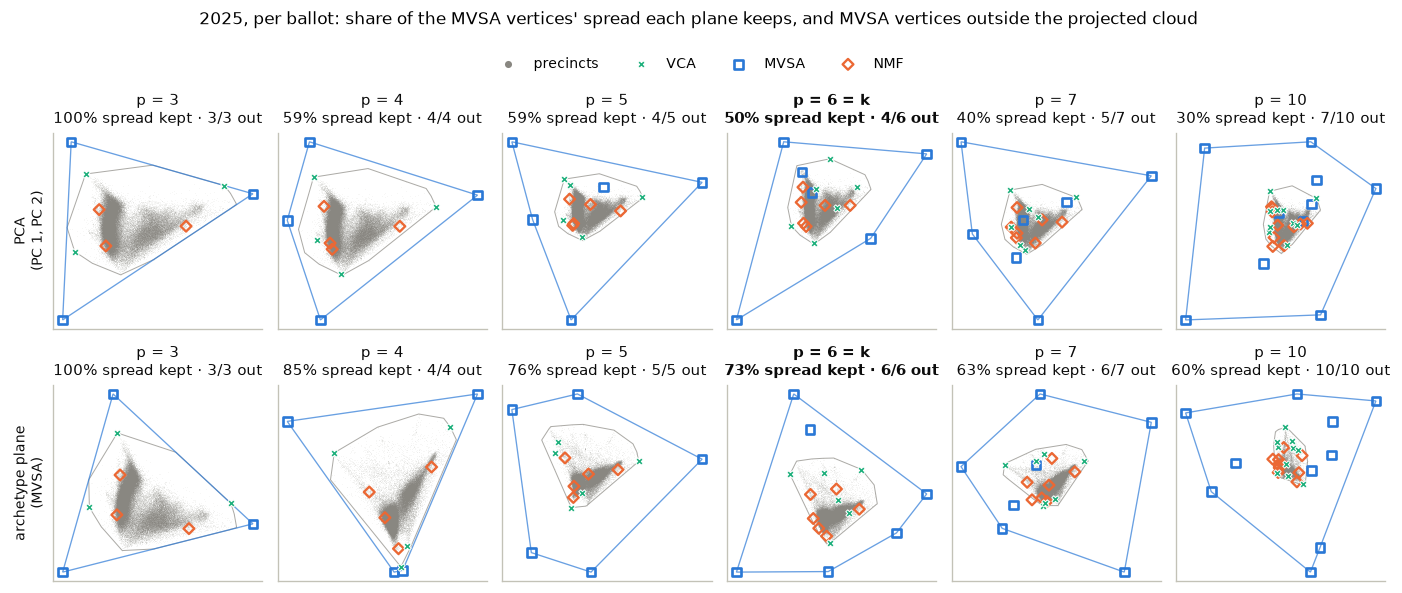

In [10]:
def compare(norm, year):
    C = COORDS[norm, year]
    k = RUNS[norm, year]["k"]
    fig, axes = plt.subplots(2, len(P_PLANE), figsize=(1.95 * len(P_PLANE), 4.6))
    for c, p in enumerate(P_PLANE):
        for r, name in enumerate(PLANES):
            plane_panel(axes[r, c], C[p][name],
                        f"p = {p}" + (" = k" if p == k else "")
                        + f"\n{C[p][name]['captured']:.0%} spread kept")
            if p == k:
                axes[r, c].title.set_fontweight("bold")
        for r, name in enumerate(PLANES):
            axes[r, 0].set_ylabel(PLANES[name].replace(" (", "\n("), fontsize=8.5, color=INK)
    h, lab = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, lab, loc="upper center", ncol=len(lab), bbox_to_anchor=(0.5, 1.0))
    leg.legend_handles[0].set_sizes([18])
    leg.legend_handles[0].set_alpha(1)
    fig.suptitle(f"{year}, {NORMS[norm]}: share of the {PLANE_BY} vertices' spread each plane keeps, "
                 f"and {PLANE_BY} vertices outside the projected cloud", y=1.06)
    fig.tight_layout()
    return fig


compare("ballot", "2025")
plt.show()

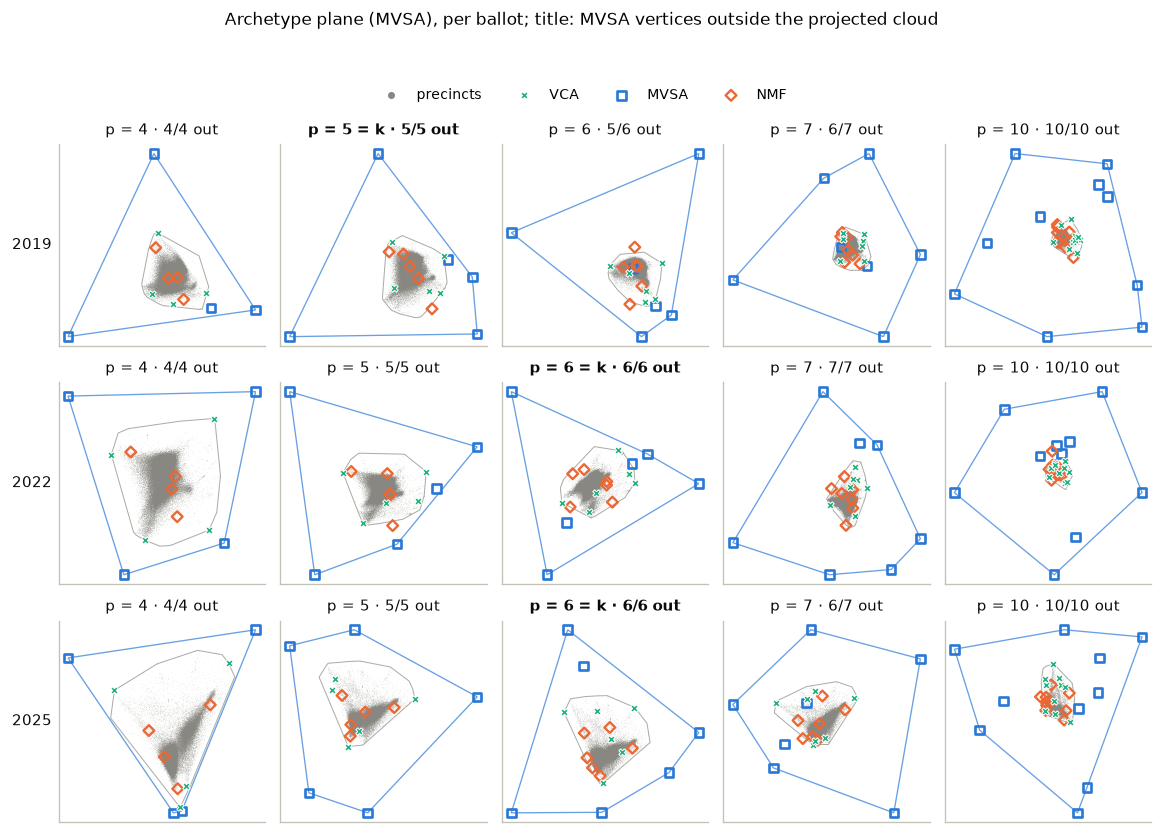

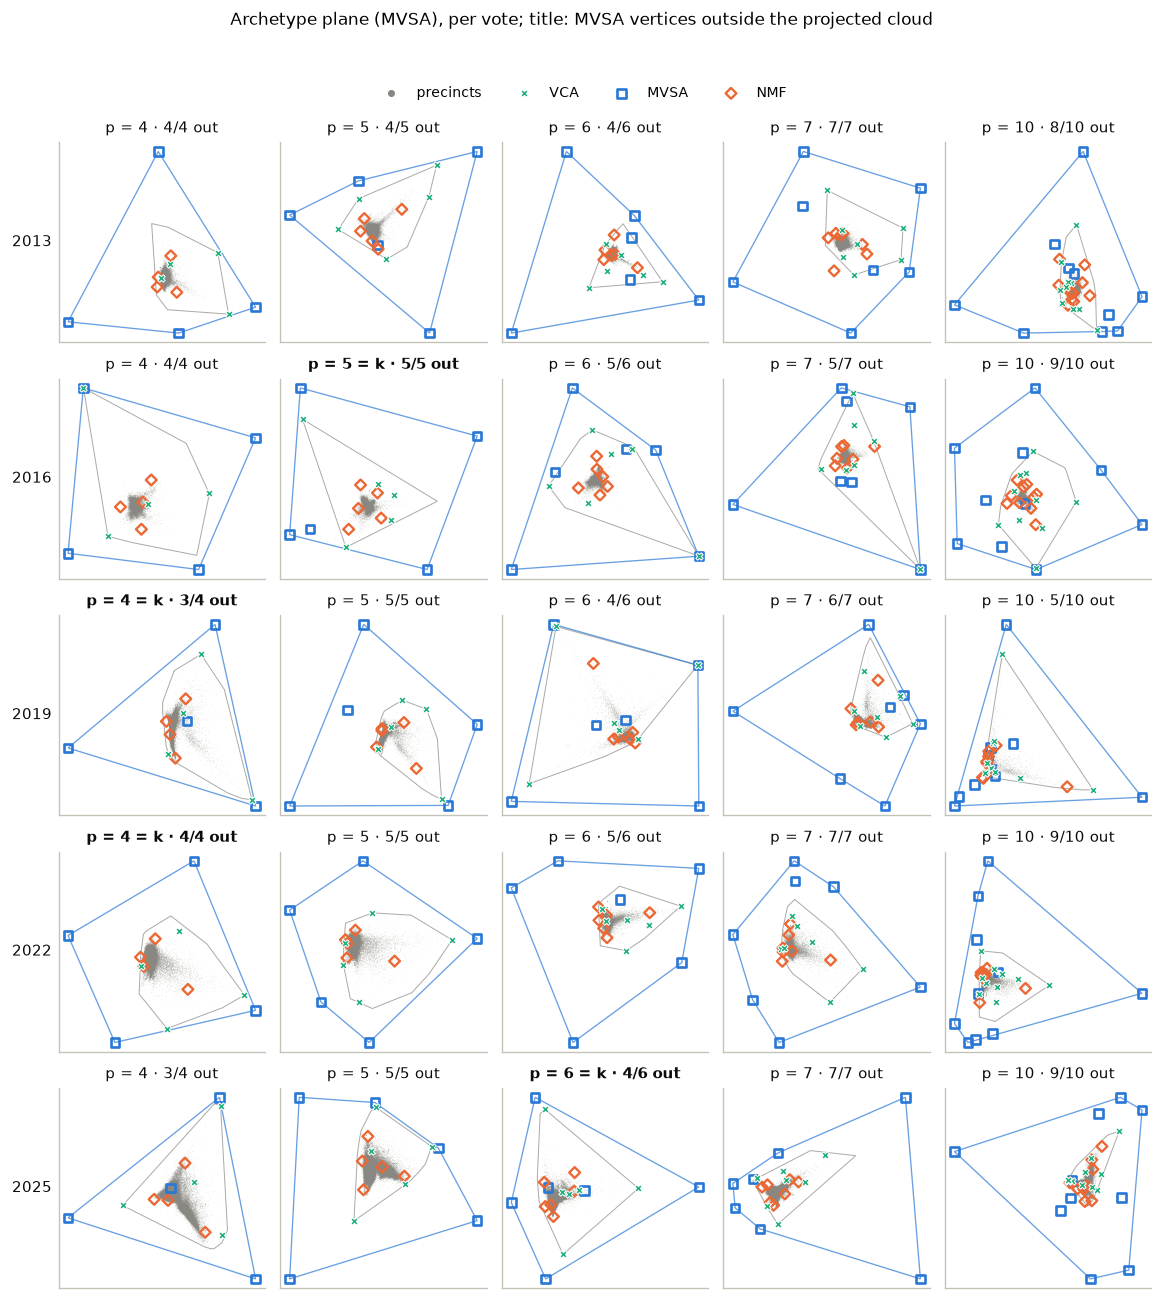

In [11]:
def plane_grid(norm):
    years = [y for n, y in COMBOS if n == norm]
    ps = [p for p in P_PLANE if p >= 4]
    fig, axes = plt.subplots(len(years), len(ps), squeeze=False,
                             figsize=(1.95 * len(ps), 1.95 * len(years) + 0.5))
    for r, year in enumerate(years):
        k = RUNS[norm, year]["k"]
        for c, p in enumerate(ps):
            plane_panel(axes[r, c], COORDS[norm, year][p]["arch"],
                        f"p = {p}" + (" = k" if p == k else ""))
            if p == k:
                axes[r, c].title.set_fontweight("bold")
        axes[r, 0].set_ylabel(year, rotation=0, ha="right", va="center", fontsize=9, color=INK)
    h, lab = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, lab, loc="upper center", ncol=len(lab), bbox_to_anchor=(0.5, 1.0))
    leg.legend_handles[0].set_sizes([18])
    leg.legend_handles[0].set_alpha(1)
    fig.suptitle(f"Archetype plane ({PLANE_BY}), {NORMS[norm]}; "
                 f"title: {PLANE_BY} vertices outside the projected cloud",
                 y=1.0 + 0.25 / len(years))
    fig.tight_layout()
    return fig


for norm in NORMS:
    plane_grid(norm)
    plt.show()

**How many vertices does each plane show outside?** Per run and $p$: the
$\mathrm{MVSA}$ vertices outside the projected cloud on the PCA plane and on the
archetype plane, against the number outside the precincts' convex hull in the
$p - 1$ PCs (a linear program per vertex: is it a convex combination of the
precincts?). By the one-way rule a plane can only undercount. The second table
is the share of the vertices' spread around their mean that each plane keeps.

In [12]:
rows = []
for (norm, year), C in COORDS.items():
    for p, c in C.items():
        rows.append({"normalization": NORMS[norm], "year": year, "p": p,
                     "PCA": c["PCA"]["outside"], "arch": c["arch"]["outside"],
                     "true": int(outside_lp(c["Z"], c["Ze"][PLANE_BY]).sum()),
                     "kept PCA": c["PCA"]["captured"], "kept arch": c["arch"]["captured"]})
shown = pd.DataFrame(rows).set_index(["normalization", "year", "p"])
assert (shown["PCA"] <= shown["true"]).all() and (shown["arch"] <= shown["true"]).all()

(shown.assign(cell=lambda d: d["PCA"].astype(str) + " / " + d["arch"].astype(str)
              + " of " + d["true"].astype(str))["cell"]
      .unstack("p").rename(columns=lambda p: f"p = {p}")
      .style.set_caption(f"{PLANE_BY} vertices outside the projected cloud: "
                         "PCA plane / archetype plane of outside in p − 1 PCs"))

In [13]:
(shown.assign(cell=lambda d: d["kept PCA"].map("{:.0%}".format) + " → "
              + d["kept arch"].map("{:.0%}".format))["cell"]
      .unstack("p").rename(columns=lambda p: f"p = {p}")
      .style.set_caption(f"share of the {PLANE_BY} vertices' spread kept: PCA plane → archetype plane"))

## Reading (draft, from the run above)

**Toy.** It reproduces the paper. MVSA lands on the true archetypes (matched
error 0.015 at $p = 3$, 0.005 at $p = 10$; the paper's Table 1 has 0.01 and 0.06).
VCA stays on the edge of the cloud, inside the true simplex (0.41, 1.33), and NMF
misses as well (0.30, 1.39). At $p = 10$ two PCs hold 44% of the variance, so
vertices outside the cloud in nine dimensions can project onto it, as in the
paper's panel (b).

**Senatorial data.**

- **$p = 2$:** MVSA and VCA coincide (same endpoints, same min loading): the
  segment's minimum-volume fit is VCA's pair of extreme precincts.
- **$p = 3$:** in every year and both normalizations the MVSA triangle encloses
  the cloud with its corners about 2–4 cloud radii out.
- **Up to and past HySime $k$:** the MVSA vertices keep moving out. Per ballot,
  the median vertex is 4–5.5 radii out at $k$ and 12–16 at $p = 12$, and the most
  negative loading reaches about $-12$ vote/ballot. Per vote, raw distances are
  ten times smaller, but so is the cloud: in radii the overshoot is about as
  large at $k$ (4–8), then stays between about 4 and 13 (2013 peaks at 13.5
  at $p = 6$) instead of growing. The per-vote min loading stays above $-1.1$ vote/vote.
- **NMF** stays within about 2.5 radii of the cloud at every $p$ (no negative
  loadings), and
  **VCA** on its edge (small negative loadings, from projecting its picks onto
  the subspace it fits).
- **UMAP** shows which lobe or tip each archetype points at: at small $p$ MVSA
  and VCA mark the same tips. At larger $p$ the far-out MVSA vertices are pulled
  back inside the cloud, so UMAP alone would hide the overshoot the PCA panels and
  the table show.
- **Archetype plane.** From $p = 4$ every MVSA vertex is outside the precincts'
  hull in the first $p - 1$ PCs, in every run (at $p = 3$ all but one: a 2016
  per-vote vertex that is a precinct). Neither plane shows them all. Over
  $p = 4, 5, 6, 7, 10$ and the eight runs, the PCA plane shows 224 of the 256
  vertices outside and the archetype plane 229. The archetype plane always keeps
  more of the vertices' spread (it is fit to do so: 39–93% against 26–88%), but
  it shows more vertices outside in only 14 of the 40 cases and fewer in 10:
  the directions that spread the vertices also spread the cloud's extreme
  precincts, which can cover a vertex again. It helps most for 2025 per ballot
  ($p = 6$: 4 of 6 outside on PCA, all 6 here; $p = 10$: 7 against 10) and 2022
  per vote ($p = 7$: 5 against 7; $p = 10$: 6 against 9), and hurts most for
  2019 per vote at $p = 10$ (8 against 5). Read the two planes together, and
  the distance table for how far out the vertices are.